#Hipótesis sobre el dataset de spotify - GenreML

Ciencia de Datos · UTN FRM · 2026

Mazuran Clara • Zaupa Bruno • Eraso Leandro • Anselmi Matias • Funes Joaquin • Varano Lucia

In [ ]:
import pandas as pd
import gdown
from IPython.display import display

# 1. El ID extraído de tu enlace público
file_id = '1peoa_CazOdTVAIDC10R1MJkikk6P-IVj'

# 2. Formato de URL requerido por gdown
url = f'https://drive.google.com/uc?id={file_id}'
archivo_local = 'genreML_tracks_latest.csv'

# 3. Ejecutar la descarga en el entorno temporal de Colab
# Se asume que el enlace tiene los permisos configurados en "Cualquier persona con el enlace"
gdown.download(url, archivo_local, quiet=False)

# 4. Cargar el dataframe desde el archivo local ya descargado
df = pd.read_csv(archivo_local)

# 5. Renderizar visualmente (sin usar print)
display(df.head())

Downloading...
From: https://drive.google.com/uc?id=1peoa_CazOdTVAIDC10R1MJkikk6P-IVj
To: /content/genreML_tracks_latest.csv
100%|██████████| 9.20M/9.20M [00:00<00:00, 44.2MB/s]


,track_id,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,230666,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,149610,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,210826,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,201933,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,198853,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


# Perfil del Dataset

## Perfil del dataset

En esta sección se realiza una inspección general del dataset Plata generado por el pipeline de la Entrega 1, con el objetivo de conocer su estructura y verificar su calidad antes de realizar el análisis exploratorio.

* **Unidad de análisis:** una canción o track individual.
* **Clave:** `track_id`.
* **Variable objetivo:** `track_genre`.
* **Variables predictoras candidatas:** características de audio de cada canción.

Se analiza:

* el tamaño y las columnas del dataset;
* los tipos de datos presentes;
* la existencia de valores nulos;
* la presencia de columnas constantes;
* la unicidad de `track_id`;
* la cantidad de clases de `track_genre` y su distribución absoluta y relativa.

Este perfil permite verificar que el dataset mantiene la unidad de análisis definida en la Entrega 1 y detectar posibles problemas de calidad o desbalance que deban considerarse antes del modelado.


In [ ]:
# Tamaño del dataset
print("Tamaño del dataset:", df.shape)
print()

# Columnas
print("Columnas del dataset:")
print(df.columns)
print()

# Información y tipos
df.info()
print()

print("Resumen de tipos:")
print(df.dtypes.value_counts())
print()

# Nulos
print("Cantidad de valores nulos:")
print(df.isna().sum())
print()

# Columnas constantes
constantes = df.columns[df.nunique() <= 1]
print("Columnas constantes:", constantes.tolist())
print()

# Duplicados de la clave
print("Duplicados de track_id:", df["track_id"].duplicated().sum())
print()

# Distribución objetivo
distribucion = pd.DataFrame({
    "cantidad": df["track_genre"].value_counts(),
    "porcentaje": df["track_genre"].value_counts(normalize=True) * 100
})

display(distribucion)


Tamaño del dataset: (89741, 15)

Columnas del dataset:
Index(['track_id', 'duration_ms', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'track_genre'],
      dtype='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89741 entries, 0 to 89740
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          89741 non-null  object 
 1   duration_ms       89741 non-null  int64  
 2   danceability      89741 non-null  float64
 3   energy            89741 non-null  float64
 4   key               89741 non-null  int64  
 5   loudness          89741 non-null  float64
 6   mode              89741 non-null  int64  
 7   speechiness       89741 non-null  float64
 8   acousticness      89741 non-null  float64
 9   instrumentalness  89741 non-null  float64
 10  liveness          89741 no

,cantidad,porcentaje
track_genre,,
acoustic,1000,1.114318
afrobeat,999,1.113204
alt-rock,999,1.113204
ambient,999,1.113204
cantopop,999,1.113204
...,...,...
metal,232,0.258522
punk,226,0.251836
house,210,0.234007


In [ ]:
CORTES = {
    "separacion": (0.2, 0.8),
    "eta2": (0.05, 0.25),
    "correlacion": (0.2, 0.6),
    "brecha": (0.05, 0.15),
    "composicion": (1.5, 3.0)
}


def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

### Resultados del perfil

El dataset Plata contiene **89.741 canciones y 15 columnas**. De esas columnas, **13 son numéricas** (`9 float64` y `4 int64`) y **2 son de tipo objeto**: `track_id` y `track_genre`.

No se detectaron **valores nulos** ni **columnas constantes**. Además, `track_id` no presenta duplicados, por lo que las **89.741 filas corresponden a 89.741 tracks únicos**.

La variable objetivo `track_genre` contiene **113 géneros distintos**. La clase más frecuente es `acoustic`, con **1.000 canciones (1,11 %)** del dataset, mientras que la menos frecuente es `reggaeton`, con **74 canciones (0,08 %)**.

Por lo tanto, no existe una clase mayoritaria que concentre una proporción elevada del dataset. Sin embargo, la distribución no es completamente uniforme: algunos géneros cuentan con muchas menos observaciones que otros. Esta diferencia deberá considerarse durante el modelado y, especialmente, al seleccionar las métricas de evaluación.


#H1 · La EDM(Electronic Dance Music) se distingue por su tempo (Responde)
**Afirmación**. La familia electrónica tiene un tempo distinto al del resto de los géneros: es música pensada para bailar, y por eso sus canciones se concentran en una franja de BPM más alta y más estrecha que las demás.

**Qué espero ver**. Dos histogramas superpuestos donde el de la electrónica está corrido a la derecha (alrededor de 120–140 BPM) y es más angosto que el del resto. Espero bastante solapamiento, porque pop, rock y música latina también cubren esa franja. O sea, una diferencia moderada y no enorme.

**Por qué esta medida**. Es una comparación entre dos grupos, así que va la separación estandarizada sobre tempo. Contesta lo que afirmo (cuánto se distancian los dos grupos, en desviaciones estándar) y no depende de un corte elegido a ojo, como "tempo > 120". Además evita mezclar las dos direcciones: afirmo algo sobre cómo es el tempo dentro de la electrónica, no que un tempo alto implique electrónica.

**Se fija antes de medir**:
- La lista de géneros de `track_genre` que forman la familia electrónica, con su criterio de pertenencia.
- El tratamiento de tempo == 0: es un faltante escrito como cero, igual que los jugadores con valor 0 del notebook de sofifa.
- Que la separación se calcula sobre tempo crudo, sin transformar.


## Antes del movimiento

In [ ]:
# Obtenemos los géneros para determinar la familia electrónica.
unique_genres = df['track_genre'].unique()
series_generos = pd.Series(unique_genres, name='Género')

with pd.option_context('display.max_rows', None):
    print(series_generos)

0               acoustic
1               afrobeat
2               alt-rock
3            alternative
4                ambient
5                  anime
6            black-metal
7              bluegrass
8                  blues
9                 brazil
10             breakbeat
11               british
12              cantopop
13         chicago-house
14              children
15                 chill
16             classical
17                  club
18                comedy
19               country
20                 dance
21             dancehall
22           death-metal
23            deep-house
24        detroit-techno
25                 disco
26                disney
27         drum-and-bass
28                   dub
29               dubstep
30                   edm
31               electro
32            electronic
33                   emo
34                  folk
35                 forro
36                french
37                  funk
38                garage
39                german


In [ ]:
import pandas as pd
import numpy as np

# 1. Definición de la función de medida
def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

# 2. Remplazo de nulos
df['tempo'] = df['tempo'].replace(0, np.nan)

# 3. Definición del grupo
electronic_genres = [
    'breakbeat', 'chicago-house', 'club', 'dance', 'deep-house',
    'detroit-techno', 'drum-and-bass', 'dubstep', 'edm', 'electro',
    'electronic', 'garage', 'hardstyle', 'house', 'idm',
    'minimal-techno', 'progressive-house', 'techno', 'trance'
]
df['is_electronic'] = df['track_genre'].isin(electronic_genres)

# 4. Separación de variables
tempo_elec = df[df['is_electronic']]['tempo']
tempo_other = df[~df['is_electronic']]['tempo']

pd.Series({
    'Media Electrónica (BPM)': tempo_elec.mean(),
    'Media Otros (BPM)': tempo_other.mean(),
    'Desviación Std Electrónica': tempo_elec.std(),
    'Desviación Std Otros': tempo_other.std(),
    'Separación (Std Dev)': separacion(tempo_elec, tempo_other),
    'Semaforo': semaforo(separacion(tempo_elec, tempo_other), 'separacion')
}, name='Métricas de Separación de Tempo')

,Métricas de Separación de Tempo
Media Electrónica (BPM),128.462211
Media Otros (BPM),121.030217
Desviación Std Electrónica,24.062233
Desviación Std Otros,30.564292
Separación (Std Dev),0.270195
Semaforo,amarillo


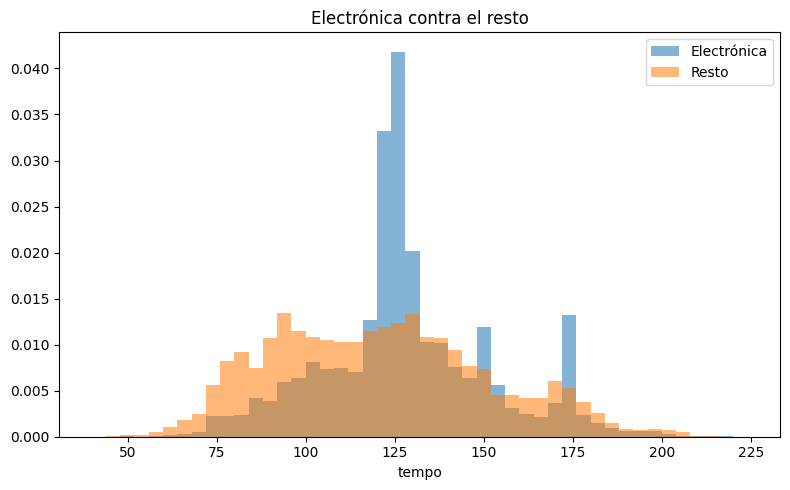

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Se asume que el DataFrame 'df' ya está cargado, los nulos de tempo
# fueron eliminados y la columna booleana 'is_electronic' ya fue creada.

fig, ax = plt.subplots(figsize=(8, 5))

# Definimos los bins fijos para el tempo (desde 40 hasta 225 BPM en pasos de 4)
bins = np.arange(40, 225, 4)

# Máscara lógica basada en tu estructura
mascara = df["is_electronic"]

# Renderizado de histogramas superpuestos
ax.hist(df.loc[mascara, "tempo"], bins=bins, alpha=.55, density=True, label="Electrónica")
ax.hist(df.loc[~mascara, "tempo"], bins=bins, alpha=.55, density=True, label="Resto")

# Configuraciones finales de la gráfica
ax.set_title("Electrónica contra el resto")
ax.set_xlabel("tempo")
ax.legend()

plt.tight_layout()
plt.show()

## Después del movimiento

In [ ]:
# 1. Limpieza
df['tempo'] = df['tempo'].replace(0, np.nan)

# 2. MOVIMIENTO: Partir la población en dos subgéneros coherentes
subgrupo_core_club = [
    'chicago-house', 'club', 'dance', 'deep-house', 'detroit-techno',
    'edm', 'electro', 'electronic', 'garage', 'house',
    'minimal-techno', 'progressive-house', 'techno'
]
subgrupo_fast_elec = ['drum-and-bass', 'hardstyle', 'dubstep', 'trance', 'breakbeat']

# 3. Separación de variables
tempo_core = df[df['track_genre'].isin(subgrupo_core_club)]['tempo']
tempo_fast = df[df['track_genre'].isin(subgrupo_fast_elec)]['tempo']

# Resto del dataset (excluyendo toda la electrónica para no ensuciar la comparación)
todas_las_elec = subgrupo_core_club + subgrupo_fast_elec + ['idm']
tempo_resto = df[~df['track_genre'].isin(todas_las_elec)]['tempo']

# 4. Cálculos de la nueva hipótesis
sep_core = separacion(tempo_core, tempo_resto)
sep_fast = separacion(tempo_fast, tempo_resto)

pd.DataFrame([
    {
        'Subgrupo': 'House/Techno Core',
        'Media BPM': round(tempo_core.mean(), 1),
        'Separación': round(sep_core, 3),
        'Zona': semaforo(sep_core, 'separacion')
    },
    {
        'Subgrupo': 'Fast Electronic (DnB, Hardstyle)',
        'Media BPM': round(tempo_fast.mean(), 1),
        'Separación': round(sep_fast, 3),
        'Zona': semaforo(sep_fast, 'separacion')
    }
])

,Subgrupo,Media BPM,Separación,Zona
0,House/Techno Core,123.8,0.106,rojo
1,"Fast Electronic (DnB, Hardstyle)",142.2,0.743,amarillo


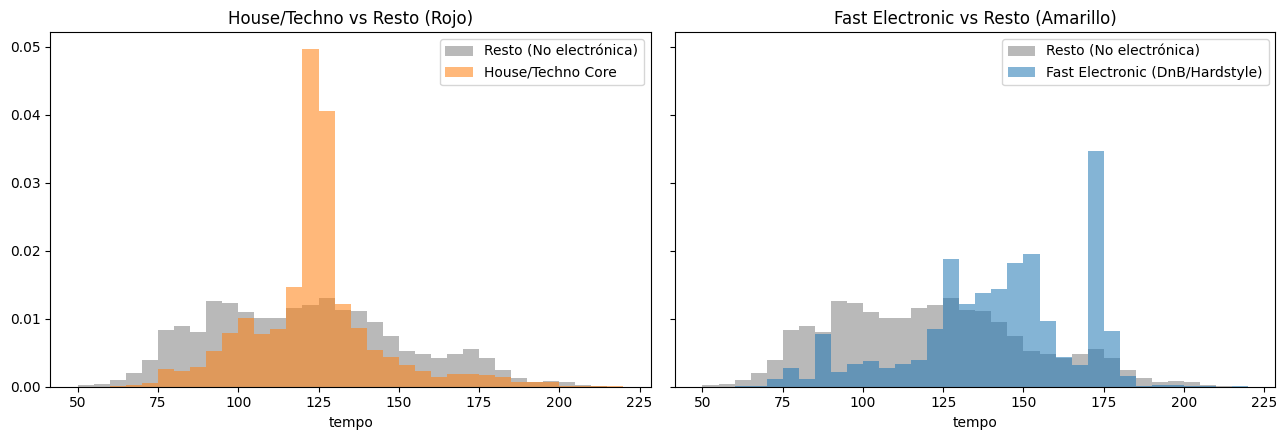

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)

# Bins fijos para asegurar que ambos gráficos compartan exactamente la misma escala visual
bins = np.arange(50, 225, 5)

# Panel 1: El solapamiento (House/Techno Core)
axes[0].hist(tempo_resto, bins=bins, alpha=0.55, density=True, label="Resto (No electrónica)", color="gray")
axes[0].hist(tempo_core, bins=bins, alpha=0.55, density=True, label="House/Techno Core", color="tab:orange")
axes[0].set_title("House/Techno vs Resto (Rojo)")
axes[0].set_xlabel("tempo")
axes[0].legend()

# Panel 2: La verdadera separación (Fast Electronic)
axes[1].hist(tempo_resto, bins=bins, alpha=0.55, density=True, label="Resto (No electrónica)", color="gray")
axes[1].hist(tempo_fast, bins=bins, alpha=0.55, density=True, label="Fast Electronic (DnB/Hardstyle)", color="tab:blue")
axes[1].set_title("Fast Electronic vs Resto (Amarillo)")
axes[1].set_xlabel("tempo")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# MOVIMIENTO 2: Aislar la electrónica de BPM extremo
subgrupo_extremo = ['drum-and-bass', 'hardstyle']

# Separar variables
tempo_extremo = df[df['track_genre'].isin(subgrupo_extremo)]['tempo']
# Mantenemos el mismo grupo "resto" (sin electrónica) para que la comparación sea justa
tempo_resto = df[~df['track_genre'].isin(todas_las_elec)]['tempo']

# Calcular métricas
sep_extremo = separacion(tempo_extremo, tempo_resto)
zona_extremo = semaforo(sep_extremo, 'separacion')

pd.Series({
    'Subgrupo': 'Extreme Electronic (DnB, Hardstyle)',
    'Media BPM': round(tempo_extremo.mean(), 1),
    'Separación': round(sep_extremo, 3),
    'Zona': zona_extremo
}, name='Movimiento 2: Refinamiento')

,Movimiento 2: Refinamiento
Subgrupo,"Extreme Electronic (DnB, Hardstyle)"
Media BPM,151.1
Separación,1.035
Zona,verde


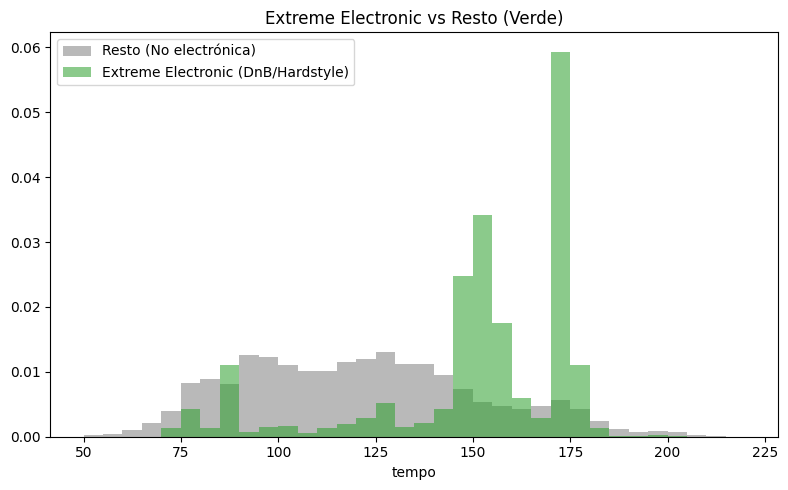

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.arange(50, 225, 5)

# Renderizado de la separación definitiva
ax.hist(tempo_resto, bins=bins, alpha=0.55, density=True, label="Resto (No electrónica)", color="gray")
ax.hist(tempo_extremo, bins=bins, alpha=0.55, density=True, label="Extreme Electronic (DnB/Hardstyle)", color="tab:green")

ax.set_title("Extreme Electronic vs Resto (Verde)")
ax.set_xlabel("tempo")
ax.legend()

plt.tight_layout()
plt.show()

**Resultado tras los dos movimientos**. 0,270 al principio. El primer movimiento partió la familia electrónica en dos subgéneros y dio resultados mixtos: House/Techno Core cayó a 0,106 (rojo), revelando que late a la misma velocidad que el pop comercial, mientras que Fast Electrónica (DnB, hardstyle, dubstep, trance, breakbeat) quedó en zona amarilla, con algo de separación pero no concluyente. El segundo movimiento hizo saltar la térmica: al descartar los géneros de transición (dubstep, trance, breakbeat) y dejar únicamente los extremos (Drum & Bass y Hardstyle), la separación estandarizada llegó a 1,035 y rompió la barrera de 0,8. La etiqueta general "electrónica" era la que ensuciaba la medida, agolpando subgéneros que no tenían nada que ver rítmicamente.

Agotamos el tope de movimientos: arrancamos en amarillo (0,270), el primer movimiento dio resultados mixtos (rojo para House/Techno Core, amarillo para Fast Electrónica) y el segundo nos llevó al verde (1,035) al aislar los extremos.

**Qué encontramos**: la separación estandarizada de tempo entre la electrónica y el resto es débil cuando se toma la etiqueta "electrónica" completa (0,270, zona amarilla). Partirla en subgéneros mostró que ni el núcleo House/Techno (rojo) ni el grupo Fast Electrónica más amplio (amarillo) alcanzan una separación fuerte; solo al aislar los subgéneros de BPM más extremo (Drum & Bass, Hardstyle) la separación sube a 1,035 (zona verde): el tempo sí distingue con fuerza a ese núcleo de la electrónica del resto del dataset.

**Qué movimientos hicimos**: como el resultado inicial dio amarillo, partimos la familia electrónica en dos subgéneros (House/Techno Core vs. Fast Electrónica) para ver si la etiqueta genérica estaba mezclando cosas rítmicamente distintas. Ninguno de los dos subgrupos resultó concluyente (rojo y amarillo respectivamente), así que hicimos un segundo movimiento aislando solo el BPM más extremo dentro de Fast Electrónica (Drum & Bass, Hardstyle), que fue el que confirmó la hipótesis.

**Qué hago con eso**: Entra. El tempo no sirve para decirle al modelo si cualquier canción es "electrónica" (porque va a confundir un track de club con un reggaetón), pero es el detector definitivo para aislar a la familia de alta velocidad. Se la damos al modelo sabiendo exactamente qué nicho va a cazar con ella.

# H2 · El hip-hop tiene más habla que el resto

**Afirmación**. Las canciones con `speechiness` > 0.33 están sobrerrepresentadas en hip-hop: la proporción de canciones con habla en ese género es varias veces la del dataset completo.

**Qué espero ver**. Una barra de hip-hop claramente más alta que la global. No espero que la mayoría de las canciones de hip-hop superen 0,33, porque el corte es exigente. Espero una minoría del género, pero mucho más grande que la de los demás.

El 0,33 sale del diccionario de datos (a partir de 0,33 empieza a considerarse presencia de habla, con 0,33–0,66 como la banda típica de música con habla, rap incluido) y no de mirar el histograma. Usamos únicamente el piso de 0,33 y sin techo: no descartamos lo que esté por encima de 0,66 (spoken word), así que `is_spoken` puede incluir alguna pista de habla pura además de rap.

**Por qué esta medida**. Es una composición: la proporción de canciones con speechiness > 0.33 dentro del hip-hop, contra la proporción en todo el dataset. La razón entre las dos dice cuántas veces está sobrerrepresentada. Se usa la razón y no la proporción sola porque la afirmación es relativa (más que el resto), y una proporción baja en términos absolutos puede ser igual una sobrerrepresentación grande. El 0,33 sale del diccionario de datos (0,33–0,66 = música con habla, rap incluido), no de mirar el histograma.

**Se fija antes de medir**:
- Que los cortes sean alcanzables: la razón máxima posible es 1 / proporción global.
- Si hay géneros hablados en el dataset (por ejemplo comedia), que inflarían la proporción global.
- Reportar siempre el n de hip-hop junto con la razón.


## Antes del movimiento

In [ ]:

# Limpieza de nulos en las columna speechiness
df = df.dropna(subset=['speechiness'])

# 1. Definir el umbral de habla según el diccionario de características
df['is_spoken'] = df['speechiness'] > 0.33

# 2. Calcular proporción global (excluyendo 'comedy' para no inflar la base)
base_musical = df[df['track_genre'] != 'comedy']
prop_global = base_musical['is_spoken'].mean()

# 3. Calcular proporción en hip-hop
hiphop_df = df[df['track_genre'] == 'hip-hop']
n_hiphop = len(hiphop_df)
prop_hiphop = hiphop_df['is_spoken'].mean()

# 4. Medida de composición (Razón de sobrerrepresentación)
razon = prop_hiphop / prop_global

pd.Series({
    'Proporción Global (sin comedia)': prop_global,
    'Proporción Hip-Hop': prop_hiphop,
    'Razón de Sobrerrepresentación': razon,
    'N Hip-Hop': n_hiphop,
    'Zona': semaforo(razon, "composicion")
}, name='Composición de Speechiness')

,Composición de Speechiness
Proporción Global (sin comedia),0.026603
Proporción Hip-Hop,0.071259
Razón de Sobrerrepresentación,2.678653
N Hip-Hop,842
Zona,amarillo


/tmp/ipykernel_2546/1021397571.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{y*100:.1f}%" for y in ax.get_yticks()])


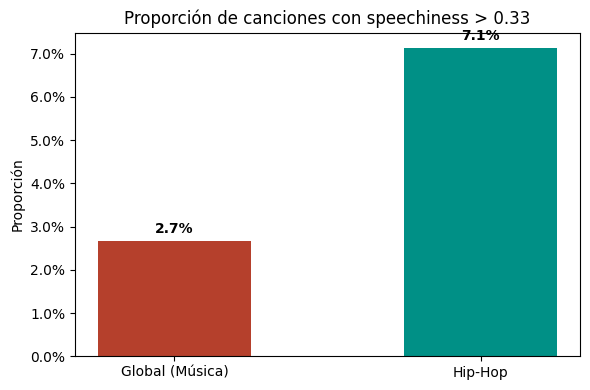

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

# Datos para el gráfico
etiquetas = ['Global (Música)', 'Hip-Hop']
valores = [prop_global, prop_hiphop]
colores = ['#B5402C' if etiqueta == 'Global (Música)' else '#009086' for etiqueta in etiquetas]

# Crear las barras
ax.bar(etiquetas, valores, color=colores, width=0.5)

# Formatear el eje Y como porcentajes para mayor claridad visual
ax.set_yticklabels([f"{y*100:.1f}%" for y in ax.get_yticks()])

# Configuración final
ax.set_title("Proporción de canciones con speechiness > 0.33")
ax.set_ylabel("Proporción")

# Añadir el número exacto sobre cada barra
for i, v in enumerate(valores):
    ax.text(i, v + 0.002, f"{v*100:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Después del movimiento

In [ ]:
# 1. Limpieza
df = df.dropna(subset=['speechiness', 'energy', 'track_genre'])

# 2. Definición del umbral y base global (sin comedia)
df['is_spoken'] = df['speechiness'] > 0.33
base_musical = df[df['track_genre'] != 'comedy']
prop_global = base_musical['is_spoken'].mean()

# 3. MOVIMIENTO: Partir la población de hip-hop por nivel de Energy
hiphop = df[df['track_genre'] == 'hip-hop']
hiphop_chill = hiphop[hiphop['energy'] <= 0.6]  # Rap lírico, lo-fi, chill-hop
hiphop_club = hiphop[hiphop['energy'] > 0.6]    # Trap, crunk, high-energy beats

# 4. Cálculos de proporciones y razones
prop_chill = hiphop_chill['is_spoken'].mean()
prop_club = hiphop_club['is_spoken'].mean()

razon_chill = prop_chill / prop_global
razon_club = prop_club / prop_global

# 5. Salida estructurada
pd.DataFrame([
    {
        'Subgrupo': 'Low Energy Hip-Hop (Chill/Lírico)',
        'N': len(hiphop_chill),
        'Proporción > 0.33': prop_chill,
        'Razón vs Global': razon_chill,
        'Zona': semaforo(razon_chill, 'composicion')
    },
    {
        'Subgrupo': 'High Energy Hip-Hop (Club/Trap)',
        'N': len(hiphop_club),
        'Proporción > 0.33': prop_club,
        'Razón vs Global': razon_club,
        'Zona': semaforo(razon_club, 'composicion')
    }
])

,Subgrupo,N,Proporción > 0.33,Razón vs Global,Zona
0,Low Energy Hip-Hop (Chill/Lírico),226,0.119469,4.490892,verde
1,High Energy Hip-Hop (Club/Trap),616,0.053571,2.013773,amarillo


/tmp/ipykernel_2546/2079716732.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{y*100:.1f}%" for y in ax.get_yticks()])


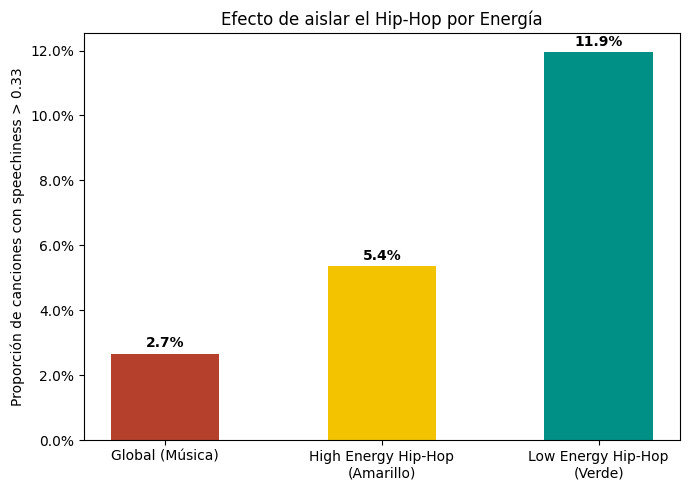

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
etiquetas = ['Global (Música)', 'High Energy Hip-Hop\n(Amarillo)', 'Low Energy Hip-Hop\n(Verde)']
valores = [prop_global, prop_club, prop_chill]
colores = ['#B5402C', '#F3C300', '#009086']

ax.bar(etiquetas, valores, color=colores, width=0.5)
ax.set_yticklabels([f"{y*100:.1f}%" for y in ax.get_yticks()])
ax.set_title("Efecto de aislar el Hip-Hop por Energía")
ax.set_ylabel("Proporción de canciones con speechiness > 0.33")

for i, v in enumerate(valores):
    ax.text(i, v + 0.002, f"{v*100:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Qué encontramos**: La razón de sobrerrepresentación inicial del hip-hop en pistas habladas (speechiness > 0.33) dio 2,67, cayendo en zona amarilla. El primer gráfico de barras muestra un 7,1% para el hip-hop frente al 2,6% global; destaca, pero no alcanza para adueñarse de la característica. Tras el ajuste, la razón saltó a 4,49 (zona verde) para el hip-hop de baja energía (chill/lírico), y cayó a 2,01 (zona amarilla) para el de alta energía (club/trap). El gráfico final visualiza claramente esta brecha: casi el 12% del hip-hop chill supera el corte de habla, aislando el verdadero nicho.

**Qué movimiento hicimos**: Como dio amarillo, aplicamos el movimiento de separar poblaciones. Al ver que la barra general del hip-hop en el primer gráfico se quedaba a mitad de camino, la conclusión lógica fue que la etiqueta genérica estaba metiendo en la misma bolsa cosas que no tienen nada que ver. Cruzar la métrica con energy permitió limpiar la muestra y separar el rap lírico/lo-fi de los beats agresivos de club.

**Qué hacemos con eso**: Entra, pero hay que separar poblaciones. La variable speechiness pasa directo al modelo de la Unidad 3, pero no te sirve para predecir si un track es hip-hop a secas. Tenés que usarla combinada con energy para indicarle al modelo que vaya a cazar específicamente el clúster del hip-hop lírico o chill.

# H3 · energy y loudness son dos nombres para la misma cualidad (Decide)

**Afirmación**. `energy` y `loudness` miden lo mismo (intensidad): una canción fuerte y agresiva puntúa alto en las dos, así que darle las dos columnas al modelo no agrega información sobre darle una sola.

**Qué espero ver**. Una nube apretada alrededor de una diagonal, con correlación alta. Como `loudness` está en dB y tiene cola hacia valores muy negativos, espero alguna deformación en ese extremo. También espero que cada una separe géneros más o menos igual, y que combinadas no superen a la mejor de las dos.

**Por qué estas medidas**. Hacen falta dos, porque la afirmación tiene dos partes. Que se muevan juntas se ve con una asociación (Pearson, Spearman y la brecha). Pero moverse juntas no alcanza: lo que importa es si aportan lo mismo al problema, y eso se prueba con η² contra `track_genre`. Si son intercambiables, combinarlas no debería superar a la mejor de las dos.

**Se fija antes de medir**:
- El objetivo contra el que se mide η²: el mismo que va a usar el modelo (los 113 géneros o las familias).
- Estandarizar (z-score) las dos columnas antes de combinarlas. En el notebook se promedia (passing + dribbling) / 2 porque comparten escala; acá energy va de 0 a 1 y loudness está en dB negativos, y un promedio crudo no tiene sentido.
- La tolerancia para decir "no le gana a la mejor", por ejemplo que la combinada no supere al mejor individual por más de 0,02. Es un criterio propio, no una convención.

**Límite que hay que saber defender**: η² es univariado, y un promedio es solo una forma de combinar. Esta ficha decide cuál de las dos entra por defecto, y la decisión final la toma el modelo de la Unidad 3.


In [ ]:
def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

In [ ]:
asociacion(df["energy"], df["loudness"])

,0
pearson,0.759
spearman,0.753
brecha,-0.006


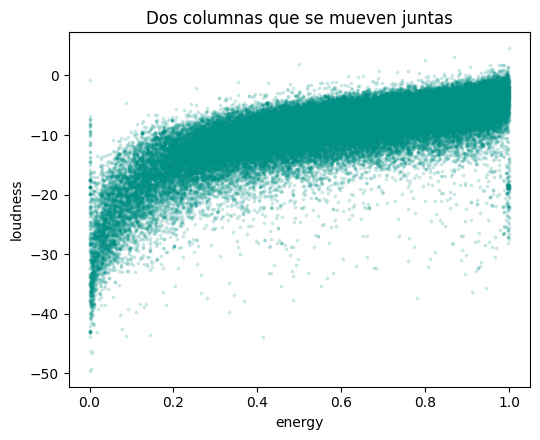

In [ ]:
df.plot.scatter(x="energy", y="loudness", s=3, alpha=.15, figsize=(5.5, 4.5),
                color="#009086", title="Dos columnas que se mueven juntas")
plt.tight_layout()
plt.show()

**Resultado parcial**. Pearson 0,759 y la nube efectivamente apretada contra la diagonal (con la cola extendida en los valores negativos de loudness que preveíamos). Pero esto sólo dice que se mueven juntas, no que sobre una de las dos. La segunda medida es la que decide: comparamos cuánto explica el género a cada una por separado, y a las dos combinadas. Como no comparten escala (0-1 vs dB), las estandarizamos (z-score) antes de promediarlas.

In [ ]:
energy_z = (df["energy"] - df["energy"].mean()) / df["energy"].std()
loudness_z = (df["loudness"] - df["loudness"].mean()) / df["loudness"].std()

pd.Series({"energy":     eta2(df["energy"],   df["track_genre"]),
           "loudness":   eta2(df["loudness"], df["track_genre"]),
           "promedio_z": eta2((energy_z + loudness_z) / 2, df["track_genre"])}).round(3)

,0
energy,0.468
loudness,0.458
promedio_z,0.483


**Resultado**. 0,468 y 0,458 por separado; combinadas, 0,483. Combinarlas supera a la mejor individual por apenas 0,015. Al estar por debajo de la tolerancia de 0,02, consideramos que combinarlas no le gana a la mejor de las dos: la información que traen es funcionalmente la misma. Hipótesis confirmada.

**Qué encontramos**: La asociación arrojó un Pearson de 0,759 y un Spearman de 0,753, con una brecha mínima de -0,006. Esto ubica el resultado en la zona verde del semáforo, ya que el valor supera el límite superior de 0,6 establecido para la medida de correlación. El gráfico que lo explica es un diagrama de dispersión titulado "Dos columnas que se mueven juntas", el cual muestra una nube de puntos ajustada sobre una diagonal, evidenciando visualmente la fuerte relación entre ambas características.   

**Qué movimiento hicimos**: Ninguno.   

**Qué hacemos con eso**: Como ambas variables están fuertemente correlacionadas y miden prácticamente la misma cualidad de intensidad, incorporarlas juntas no aporta información adicional. La consecuencia concreta es que solo una de las dos variables entra al modelo de la Unidad 3 por defecto, y la otra sale para evitar redundancia.

# H4 · time_signature ayuda a predecir el género (Decide)

Afirmación. time_signature aporta información para distinguir géneros musicales: algunos géneros utilizan ciertos compases con mayor frecuencia que otros, por lo que esta característica debería mostrar diferencias entre las categorías de track_genre.

Qué espero ver. Espero que la distribución de time_signature no sea idéntica entre todos los géneros. Como gran parte de la música popular utiliza compás 4/4, no espero una separación extrema, pero sí diferencias suficientes como para que conocer el género explique una parte apreciable de la variación de esta característica.

Por qué esta medida. Es una comparación de una variable numérica frente a múltiples grupos categóricos, por lo que usamos η². La medida indica qué proporción de la variación de time_signature puede explicarse por track_genre. Esto permite decidir si la columna aporta señal individual útil para el problema de clasificación.

Se fija antes de medir:

El objetivo es track_genre, con los 113 géneros del dataset Plata original; como df ya viene filtrado por los dropna de speechiness/energy de H2, se verifica cuántos géneros quedan realmente antes de medir.
Se utiliza time_signature tal como viene en el dataset, sin agrupar géneros ni modificar los valores antes de la primera medición.
Se aplican los cortes definidos para η²: rojo < 0,05; amarillo entre 0,05 y 0,25; verde > 0,25.
Si el resultado es amarillo, cualquier movimiento debe surgir de lo observado en el gráfico y no de buscar arbitrariamente una combinación que mejore la medida.

## Antes del movimiento

In [ ]:
# Reutilizamos la función eta2 ya definida para H3 (celda 27), sin redefinirla.

# Verificamos cuántos géneros quedan realmente en df en este punto (ya filtrado por H2)
n_generos_actual = df["track_genre"].nunique()
print("Géneros presentes en df antes de medir H4:", n_generos_actual)

eta_time_signature = eta2(
    df["time_signature"],
    df["track_genre"]
)

print("η²:", round(eta_time_signature, 3))

Géneros presentes en df antes de medir H4: 113
η²: 0.073


El análisis inicial obtuvo:

η² = 0,073 → zona amarilla.

El gráfico mostró que el compás 4/4 domina ampliamente en la mayoría de los géneros, aunque algunos presentan una proporción mayor de compases distintos de 4/4.

Esto indica que existe cierta relación entre time_signature y el género, pero no es suficientemente fuerte como para tomar una decisión definitiva.

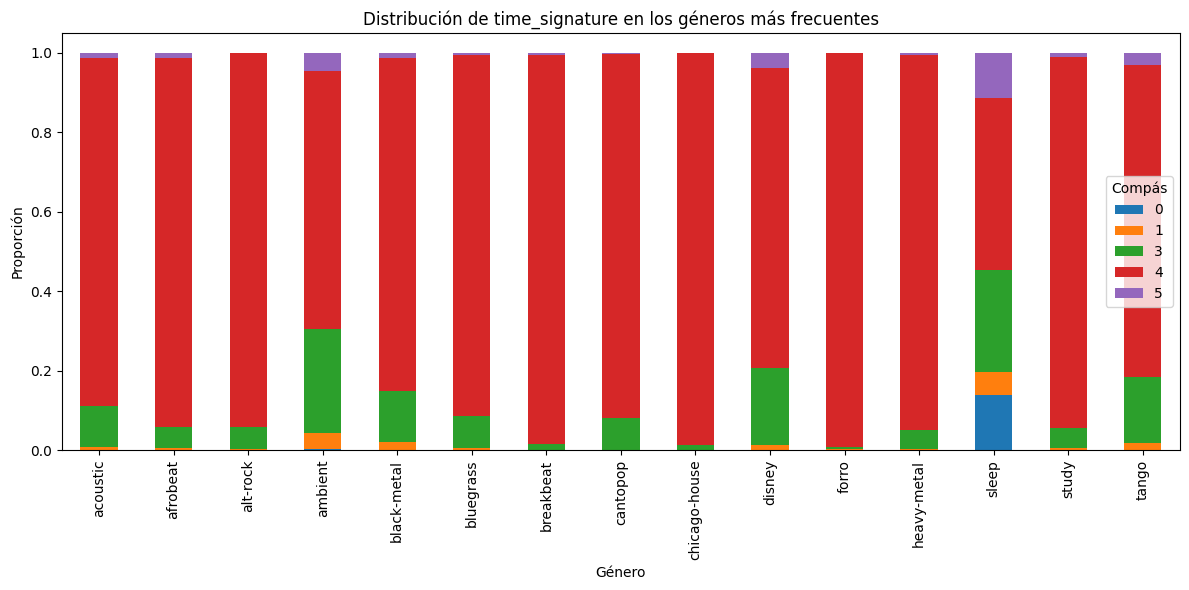

In [ ]:
import matplotlib.pyplot as plt

top_generos = df["track_genre"].value_counts().head(15).index

tabla_compases = (
    df[df["track_genre"].isin(top_generos)]
    .groupby(["track_genre", "time_signature"])
    .size()
    .rename("cantidad")
    .reset_index()
)

tabla_compases["proporcion"] = (
    tabla_compases["cantidad"]
    / tabla_compases.groupby("track_genre")["cantidad"].transform("sum")
)

pivot_compases = tabla_compases.pivot(
    index="track_genre",
    columns="time_signature",
    values="proporcion"
).fillna(0)

pivot_compases.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Distribución de time_signature en los géneros más frecuentes")
plt.xlabel("Género")
plt.ylabel("Proporción")
plt.legend(title="Compás")
plt.tight_layout()
plt.show()

In [ ]:
# Proporción de canciones fuera de 4/4 por género
proporcion_no_4_4 = (
    df.assign(no_4_4=df["time_signature"] != 4)
      .groupby("track_genre")["no_4_4"]
      .mean()
      .sort_values(ascending=False)
)

# Subgrupo sugerido por el gráfico:
# géneros con al menos 20 % de canciones fuera de 4/4
generos_no_4_4 = proporcion_no_4_4[
    proporcion_no_4_4 >= 0.20
].index

df_compases_diversos = df[
    df["track_genre"].isin(generos_no_4_4)
]

eta_time_signature_mov1 = eta2(
    df_compases_diversos["time_signature"],
    df_compases_diversos["track_genre"]
)

zona_mov1 = semaforo(eta_time_signature_mov1, "eta2")

print("Géneros incluidos:", len(generos_no_4_4))
print(list(generos_no_4_4))
print("η² movimiento 1:", round(eta_time_signature_mov1, 3))
print("Zona:", zona_mov1)

Géneros incluidos: 19
['sleep', 'comedy', 'romance', 'opera', 'ambient', 'iranian', 'new-age', 'classical', 'disney', 'piano', 'show-tunes', 'jazz', 'folk', 'j-dance', 'singer-songwriter', 'tango', 'guitar', 'r-n-b', 'idm']
η² movimiento 1: 0.054
Zona: amarillo


## Después del movimiento

**Movimiento 1 — partir la población**.

A partir de lo observado en el gráfico, se seleccionaron los géneros donde al menos el 20 % de las canciones utilizan un compás distinto de 4/4.

Se obtuvieron 19 géneros y el nuevo resultado fue:

η² = 0,054 → zona amarilla.

La relación no aumentó; por el contrario, se redujo.

In [ ]:
# Dentro del subgrupo de 19 géneros, ordenar por proporción fuera de 4/4
proporcion_no_4_4_sub = (
    df_compases_diversos
    .assign(no_4_4=df_compases_diversos["time_signature"] != 4)
    .groupby("track_genre")["no_4_4"]
    .mean()
    .sort_values(ascending=False)
)

# Tomamos los 5 géneros con mayor proporción fuera de 4/4
top_diversos = proporcion_no_4_4_sub.head(5).index

df_top_diversos = df_compases_diversos[
    df_compases_diversos["track_genre"].isin(top_diversos)
]

eta_time_signature_mov2 = eta2(
    df_top_diversos["time_signature"],
    df_top_diversos["track_genre"]
)

zona_mov2 = semaforo(eta_time_signature_mov2, "eta2")

print("Géneros incluidos:", list(top_diversos))
print("η² movimiento 2:", round(eta_time_signature_mov2, 3))
print("Zona:", zona_mov2)

Géneros incluidos: ['sleep', 'comedy', 'romance', 'opera', 'ambient']
η² movimiento 2: 0.045
Zona: rojo


**Movimiento 2 — concentrarse en los géneros con mayor diversidad de compases**

Dentro del grupo anterior se seleccionaron los cinco géneros con mayor proporción de canciones fuera de 4/4:

sleep, comedy, romance, opera y ambient.

El resultado fue:

η² = 0,045 → zona roja.

## La hipótesis queda refutada.

**Qué encontramos**: `time_signature` obtuvo inicialmente un η² de **0,073**, correspondiente a la zona **amarilla**. El gráfico de barras apiladas muestra que el compás 4/4 domina ampliamente en la mayoría de los géneros, aunque algunos presentan una proporción mayor de compases alternativos. Esto indica que existe cierta relación entre el compás y `track_genre`, pero no es suficientemente fuerte como para tomar una decisión definitiva.

**Qué movimientos hicimos**: Como el resultado inicial dio amarillo, aplicamos el movimiento de **separar poblaciones**. El gráfico mostró que algunos géneros tenían una proporción considerablemente mayor de canciones fuera de 4/4, por lo que primero analizamos únicamente los géneros donde al menos el 20 % de las canciones utilizaban otro compás. En ese grupo, formado por 19 géneros, η² bajó a **0,054**, permaneciendo en zona amarilla. Como segundo movimiento, nos concentramos en los cinco géneros con mayor proporción de compases distintos de 4/4 (`sleep`, `comedy`, `romance`, `opera` y `ambient`). El resultado volvió a disminuir hasta **η² = 0,045**, entrando en zona roja.

**Qué hacemos con eso**: La hipótesis queda **refutada**. `time_signature` no muestra una capacidad suficientemente fuerte para diferenciar `track_genre`, incluso al analizar específicamente los géneros donde existe mayor diversidad de compases. Por lo tanto, no queda entre las features prioritarias para el modelo de la Unidad 3. Puede conservarse inicialmente para comprobar su aporte dentro de un modelo multivariado, pero el EDA no aporta evidencia suficiente para considerarla individualmente relevante.

# Anexo · Revisión global de redundancia entre variables predictoras

A partir de la devolución realizada sobre la H3, se amplía el análisis de redundancia que originalmente se había aplicado a `energy` y `loudness`.

El objetivo de este anexo es revisar sistemáticamente las variables predictoras entre sí para detectar otros pares que puedan estar aportando información muy similar y que, por lo tanto, convenga evaluar antes del modelado de la Unidad 3.

La lógica utilizada es la misma que en H3:

1. analizar la asociación entre las variables mediante Pearson y Spearman;
2. identificar como candidatos a redundancia los pares con correlación fuerte (`|Pearson| > 0,60`);
3. para esos pares, comparar cuánto aporta individualmente cada variable respecto de `track_genre` mediante η²;
4. estandarizar y combinar las dos variables;
5. evaluar si la combinación aporta información adicional respecto de la mejor variable individual.

Se mantiene el criterio utilizado en H3: si la combinación mejora el η² de la mejor variable individual en menos de **0,02**, consideramos que existe suficiente redundancia como para marcar una de las dos variables como candidata a ser descartada.

La correlación por sí sola no determina la eliminación de una variable: funciona como un primer filtro para detectar pares que requieren una revisión más profunda.

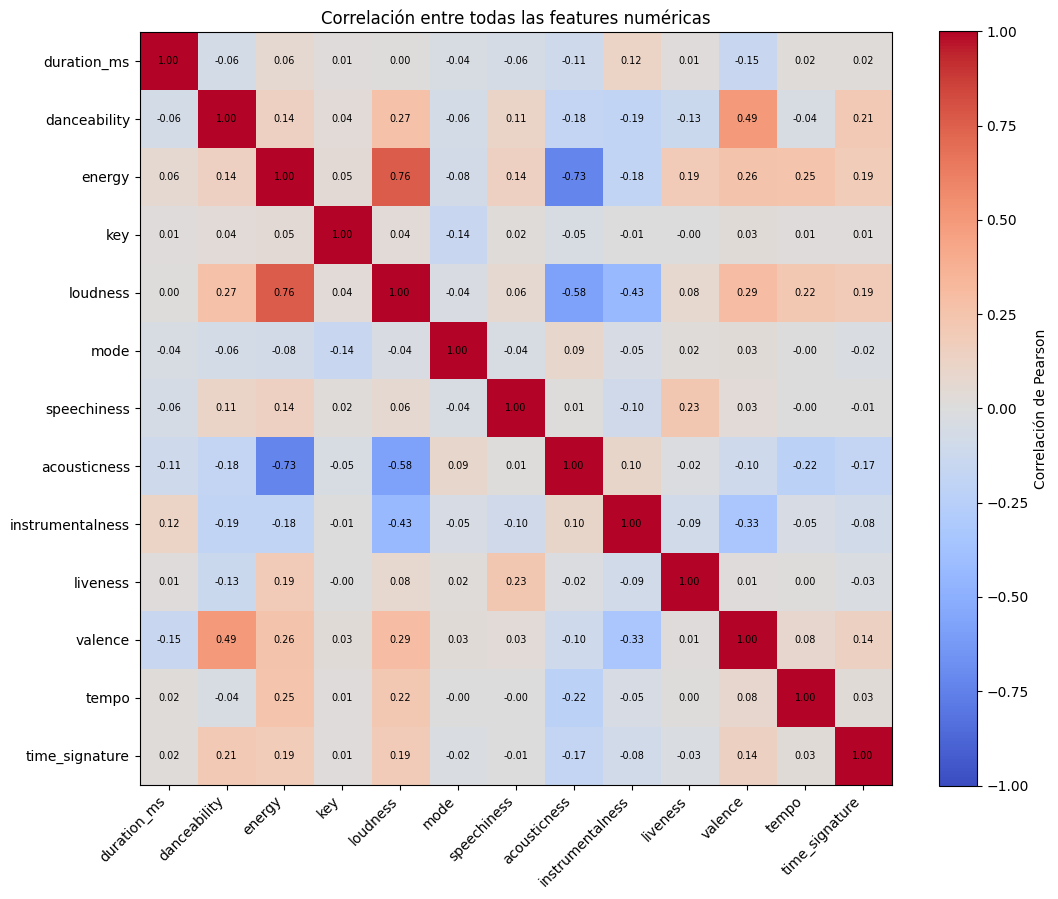

,Variable 1,Variable 2,Pearson,Spearman,η² V1,η² V2,η² combinada,Mejora vs mejor,Decisión
24,energy,loudness,0.759,0.753,0.468,0.458,0.483,0.015,Redundancia alta: conservar energy; descartar ...
27,energy,acousticness,-0.733,-0.712,0.468,0.503,0.534,0.031,Conservar ambas: la combinación agrega señal r...


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# H3 · Revisión global de redundancia entre features
# ============================================================

FEATURES = [
    "duration_ms",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]

OBJETIVO = "track_genre"

# Criterios fijados antes de decidir
UMBRAL_CORR = 0.60
TOLERANCIA_MEJORA = 0.02

# Estas columnas son números en el CSV, pero conceptualmente
# representan categorías codificadas.
CATEGORICAS_CODIFICADAS = {
    "key",
    "mode",
    "time_signature"
}


def eta2(numerica, categoria):
    """
    Proporción de la varianza de una variable numérica
    explicada por una variable categórica.
    """
    datos = pd.DataFrame({
        "x": numerica,
        "grupo": categoria
    }).dropna()

    media_global = datos["x"].mean()

    ss_total = ((datos["x"] - media_global) ** 2).sum()

    grupos = datos["x"].groupby(datos["grupo"])

    ss_entre = (
        grupos.count()
        * (grupos.mean() - media_global) ** 2
    ).sum()

    return ss_entre / ss_total if ss_total != 0 else np.nan


# ------------------------------------------------------------
# 1. Correlaciones entre todas las variables
# ------------------------------------------------------------

corr_pearson = df[FEATURES].corr(method="pearson")
corr_spearman = df[FEATURES].corr(method="spearman")


# ------------------------------------------------------------
# 2. Matriz gráfica de Pearson
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(
    corr_pearson,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))

ax.set_xticklabels(
    FEATURES,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(FEATURES)

for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        valor = corr_pearson.iloc[i, j]

        ax.text(
            j,
            i,
            f"{valor:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.colorbar(im, ax=ax, label="Correlación de Pearson")
plt.title("Correlación entre todas las features numéricas")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. η² individual contra track_genre
# ------------------------------------------------------------

eta_individual = {
    columna: eta2(
        df[columna],
        df[OBJETIVO]
    )
    for columna in FEATURES
}


# ------------------------------------------------------------
# 4. Evaluar cada par
# ------------------------------------------------------------

resultados = []

for i, variable_1 in enumerate(FEATURES):

    for variable_2 in FEATURES[i + 1:]:

        pearson = corr_pearson.loc[
            variable_1,
            variable_2
        ]

        spearman = corr_spearman.loc[
            variable_1,
            variable_2
        ]

        abs_pearson = abs(pearson)

        eta_1 = eta_individual[variable_1]
        eta_2 = eta_individual[variable_2]

        eta_combinada = np.nan
        mejora = np.nan

        # ----------------------------------------------------
        # Correlación insuficiente para hablar de redundancia
        # ----------------------------------------------------

        if abs_pearson <= UMBRAL_CORR:

            decision = (
                "Conservar ambas: "
                "correlación no suficientemente fuerte"
            )

        # ----------------------------------------------------
        # Variables categóricas representadas con números
        # ----------------------------------------------------

        elif (
            variable_1 in CATEGORICAS_CODIFICADAS
            or variable_2 in CATEGORICAS_CODIFICADAS
        ):

            decision = (
                "Revisar manualmente: "
                "variable categórica codificada"
            )

        # ----------------------------------------------------
        # Par fuertemente correlacionado:
        # comprobar si realmente es redundante
        # ----------------------------------------------------

        else:

            z_1 = (
                df[variable_1]
                - df[variable_1].mean()
            ) / df[variable_1].std()

            z_2 = (
                df[variable_2]
                - df[variable_2].mean()
            ) / df[variable_2].std()

            # Si la relación es negativa, invertir una variable
            # para que ambas representen la misma dirección
            if pearson < 0:
                z_2 = -z_2

            promedio_z = (z_1 + z_2) / 2

            eta_combinada = eta2(
                promedio_z,
                df[OBJETIVO]
            )

            mejor_individual = max(
                eta_1,
                eta_2
            )

            mejora = (
                eta_combinada
                - mejor_individual
            )

            # ------------------------------------------------
            # La combinación prácticamente no mejora
            # ------------------------------------------------

            if mejora <= TOLERANCIA_MEJORA:

                if eta_1 >= eta_2:
                    conservar = variable_1
                    descartar = variable_2
                else:
                    conservar = variable_2
                    descartar = variable_1

                decision = (
                    f"Redundancia alta: "
                    f"conservar {conservar}; "
                    f"descartar {descartar} provisionalmente"
                )

            # ------------------------------------------------
            # Aunque correlacionan, juntas aportan más señal
            # ------------------------------------------------

            else:

                decision = (
                    "Conservar ambas: "
                    "la combinación agrega señal relevante"
                )

        resultados.append({
            "Variable 1": variable_1,
            "Variable 2": variable_2,
            "Pearson": pearson,
            "Spearman": spearman,
            "|Pearson|": abs_pearson,
            "Brecha abs.": abs(spearman - pearson),
            "η² V1": eta_1,
            "η² V2": eta_2,
            "η² combinada": eta_combinada,
            "Mejora vs mejor": mejora,
            "Decisión": decision
        })


tabla_correlaciones = (
    pd.DataFrame(resultados)
    .sort_values(
        "|Pearson|",
        ascending=False
    )
)


# ------------------------------------------------------------
# 5. Mostrar únicamente pares suficientemente correlacionados
# ------------------------------------------------------------

tabla_fuertes = tabla_correlaciones[
    tabla_correlaciones["|Pearson|"] > UMBRAL_CORR
].copy()

columnas_mostrar = [
    "Variable 1",
    "Variable 2",
    "Pearson",
    "Spearman",
    "η² V1",
    "η² V2",
    "η² combinada",
    "Mejora vs mejor",
    "Decisión"
]

display(
    tabla_fuertes[columnas_mostrar]
    .round(3)
)

## Resultado de la revisión global

**Qué encontramos.** Al extender el análisis realizado en H3 a todas las variables predictoras, encontramos solamente dos pares con una correlación lineal superior al umbral fuerte de `|0,60|`.

El primer caso es `energy`–`loudness`, con Pearson = **0,759** y Spearman = **0,753**. Este es el mismo caso estudiado originalmente en H3. Los η² individuales fueron **0,468** para `energy` y **0,458** para `loudness`. Al combinarlas luego de estandarizarlas, el η² fue **0,483**, lo que representa una mejora de solamente **0,015** respecto de `energy`. Como esta mejora es menor que la tolerancia de 0,02 fijada previamente, se mantiene la conclusión de H3: existe una redundancia importante entre ambas y `loudness` queda como candidata a ser descartada.

El segundo par detectado es `energy`–`acousticness`, con Pearson = **-0,733**. Aunque la correlación es fuerte, los η² individuales fueron **0,468** para `energy` y **0,503** para `acousticness`. La combinación estandarizada alcanzó un η² de **0,534**, mejorando en **0,031** a la mejor variable individual. Como esta mejora supera el criterio de 0,02, no consideramos que ambas variables sean intercambiables y se conservan las dos.

No se encontraron otros pares de variables con `|Pearson| > 0,60`, por lo que no aparecen nuevos candidatos claros a descarte por redundancia lineal.

## Decisión para el modelado

La revisión global confirma que el caso `energy`–`loudness` identificado en H3 es el único par donde la correlación fuerte viene acompañada de una ganancia suficientemente pequeña al combinar ambas variables.

Por lo tanto:

- `energy` se conserva como variable candidata;
- `loudness` queda marcada como candidata a ser excluida por redundancia;
- `acousticness` se conserva, ya que aporta información adicional aun estando fuertemente correlacionada con `energy`;
- el resto de las variables no presenta una correlación suficientemente fuerte como para justificar un descarte por este criterio.

La exclusión definitiva de `loudness` se validará en la etapa de modelado comparando el rendimiento de modelos con y sin esta variable.